In [1]:
# Code Cell 1.1: Environment Setup
!pip install -q "qiskit>=1.3.0" "qiskit-aer>=0.16.0" "qiskit-addon-sqd>=0.12.0" pyscf ffsim "scipy>=1.12.0" numpy matplotlib

import sys
import os
import math
import itertools
import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt

import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import XXPlusYYGate
from qiskit_aer import AerSimulator
from qiskit.primitives import BitArray
from qiskit.quantum_info import Statevector

import pyscf
from pyscf import gto, scf, ao2mo, fci, cc

import qiskit_addon_sqd
from qiskit_addon_sqd.counts import bit_array_to_arrays
from qiskit_addon_sqd.subsampling import postselect_by_hamming_right_and_left
from qiskit_addon_sqd.configuration_recovery import recover_configurations
from qiskit_addon_sqd.fermion import diagonalize_fermionic_hamiltonian

import ffsim

print("Environment initialization complete! All core tools ready.")

Environment initialization complete! All core tools ready.


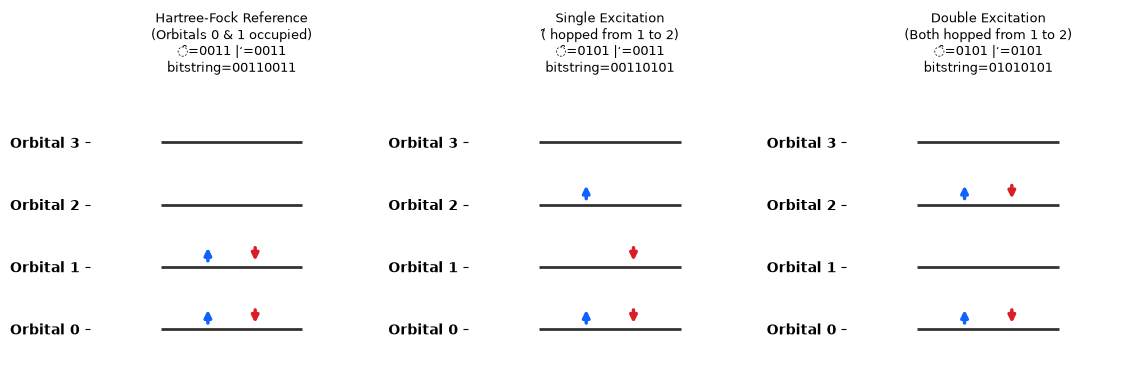

In [2]:
# Code Cell 2.1: Orbital Ladder Visualizer
def draw_molecular_configuration(alpha: str, beta: str, ax=None, title=""):
    """
    Draw an orbital-ladder diagram of a molecular electron configuration.
    alpha and beta are binary strings (e.g. '0011'), where orbital 0 is the rightmost bit.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(3.5, 3.5))
    norb = len(alpha)
    for i in range(norb):
        # Draw horizontal rung for orbital i
        ax.hlines(i, -0.3, 0.3, color="#333333", lw=2)
        # Check alpha occupancy (reading right-to-left: orbital i is index norb - 1 - i)
        if alpha[norb - 1 - i] == "1":
            ax.annotate("", (-0.1, i + 0.35), (-0.1, i + 0.05),
                        arrowprops=dict(arrowstyle="-|>", color="#0f62fe", lw=2.5))
        # Check beta occupancy
        if beta[norb - 1 - i] == "1":
            ax.annotate("", (0.1, i + 0.05), (0.1, i + 0.35),
                        arrowprops=dict(arrowstyle="-|>", color="#da1e28", lw=2.5))

    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(-0.5, norb)
    ax.set_yticks(range(norb))
    ax.set_yticklabels([f"Orbital {i}" for i in range(norb)], fontsize=10, fontweight="bold")
    ax.set_xticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"{title}\n̑={alpha} | ̒={beta}\nbitstring={beta+alpha}", fontsize=9.5)
    return ax

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.8))
draw_molecular_configuration("0011", "0011", axes[0], "Hartree-Fock Reference\n(Orbitals 0 & 1 occupied)")
draw_molecular_configuration("0101", "0011", axes[1], "Single Excitation\n(̑ hopped from 1 to 2)")
draw_molecular_configuration("0101", "0101", axes[2], "Double Excitation\n(Both hopped from 1 to 2)")
plt.tight_layout()
plt.show()

State A: 00110011
State B: 00110101
State C: 10011001
State D: 11001100


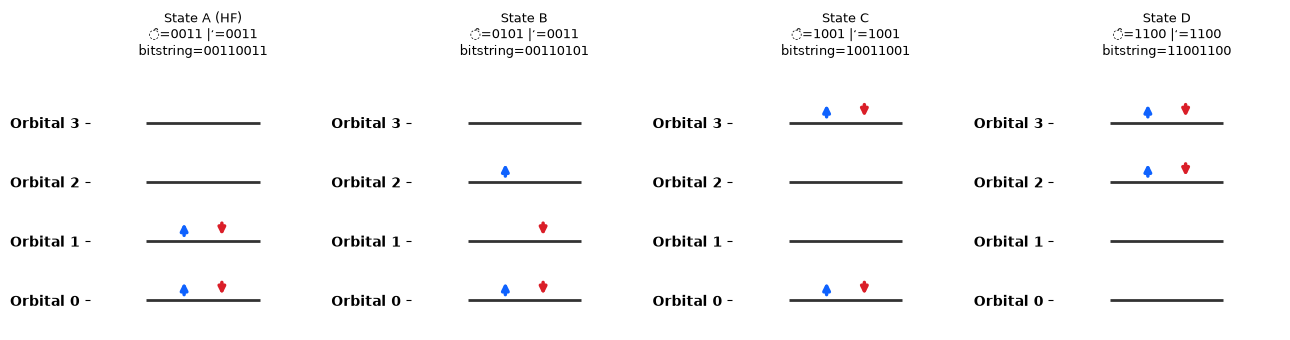

In [8]:
# Code Cell 2.2: Exercise 2 Solutions
# ================== EXERCISE 2 ==================
# 1. State A: Hartree-Fock ground state
alpha_A = "0011"  # YOUR CODE HERE: 4-character string representing alpha orbitals
beta_A  = "0011"  # YOUR CODE HERE: 4-character string representing beta orbitals
bitstring_A = beta_A + alpha_A

# 2. State B: Single excitation
alpha_B = "0101"  # YOUR CODE HERE: 4-character string representing alpha orbitals
beta_B  = "0011"  # YOUR CODE HERE: 4-character string representing beta orbitals
bitstring_B = beta_B + alpha_B

# 3. State C: Double excitation
alpha_C = "1001"  # YOUR CODE HERE: 4-character string representing alpha orbitals
beta_C  = "1001"  # YOUR CODE HERE: 4-character string representing beta orbitals
bitstring_C = beta_C + alpha_C

# 4. State D: Quadruple excitation
alpha_D = "1100"  # YOUR CODE HERE: 4-character string representing alpha orbitals
beta_D  = "1100"  # YOUR CODE HERE: 4-character string representing beta orbitals
bitstring_D = beta_D + alpha_D

print(f"State A: {bitstring_A}")
print(f"State B: {bitstring_B}")
print(f"State C: {bitstring_C}")
print(f"State D: {bitstring_D}")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
draw_molecular_configuration(alpha_A, beta_A, axes[0], "State A (HF)")
draw_molecular_configuration(alpha_B, beta_B, axes[1], "State B")
draw_molecular_configuration(alpha_C, beta_C, axes[2], "State C")
draw_molecular_configuration(alpha_D, beta_D, axes[3], "State D")
plt.tight_layout()
plt.show()

In [5]:
# Code Cell 2.3: Determinant Counting & Wavefunction Concentration
# ================== EXERCISE 3 ==================
norb = 4                # 4 spatial orbitals -> 8 qubits
n_alpha, n_beta = 2, 2  # H4 minimal basis has 2 alpha electrons and 2 beta electrons

# 1. Total mathematically possible bitstrings on 8 qubits (2 * norb)
total_possible_bitstrings = 2 ** (2 * norb)

# 2. Number of bitstrings that strictly conserve particle number (Ne = 4) and spin (Sz = 0)
spin_conserving_bitstrings = math.comb(norb, n_alpha) * math.comb(norb, n_beta)

print("=== Determinant Counting Analysis (4 Orbitals = 8 Qubits) ===")
print(f"Total mathematically possible bitstrings: {total_possible_bitstrings}")
print(f"Configurations conserving Ne=4 and Sz=0:  {spin_conserving_bitstrings}")

=== Determinant Counting Analysis (4 Orbitals = 8 Qubits) ===
Total mathematically possible bitstrings: 256
Configurations conserving Ne=4 and Sz=0:  36


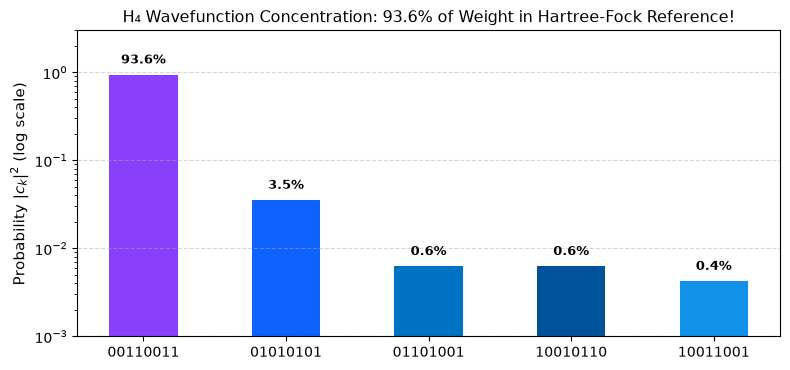

In [6]:
# Code Cell 2.4: Solve FCI using PySCF to extract exact determinant probabilities
mol_h4 = gto.M(atom="H 0 0 0; H 0 0 1.0; H 0 0 2.0; H 0 0 3.0", basis="sto-3g", verbose=0)
mf_h4 = scf.RHF(mol_h4).run()
cisolver = fci.FCI(mf_h4)
e_fci_h4, civec_h4 = cisolver.kernel()

# Dynamically construct the determinant labels for the spin-conserving sector and match their probabilities
alpha_stringss = list(itertools.combinations(range(norb), n_alpha))
beta_stringss = list(itertools.combinations(range(norb), n_beta))

det_probs = {}
for a_idx, a_occ in enumerate(alpha_stringss):
    for b_idx, b_occ in enumerate(beta_stringss):
        # Build the bitstrings (rightmost orbital is orbital 0)
        a_bits = ['0'] * norb
        for orb in a_occ: a_bits[norb - 1 - orb] = '1'
        b_bits = ['0'] * norb
        for orb in b_occ: b_bits[norb - 1 - orb] = '1'

        bs = "".join(b_bits) + "".join(a_bits)
        weight = civec_h4[a_idx, b_idx] ** 2
        det_probs[bs] = weight

# Sort the configurations by exact FCI probability
sorted_dets = sorted(det_probs.items(), key=lambda x: x[1], reverse=True)
h4_configs = [det for det, prob in sorted_dets[:5]]
h4_probabilities = [prob for det, prob in sorted_dets[:5]]
hf_weight = det_probs.get("00110011", 0.0) * 100

# 4. Bar chart of wavefunction concentration
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(h4_configs, h4_probabilities, color=["#8a3ffc", "#0f62fe", "#0072c3", "#00539a", "#1192e8"], width=0.48)
ax.set_yscale("log")
ax.set_ylim(1e-3, 3.0)
ax.set_ylabel("Probability $|c_k|^2$ (log scale)", fontsize=11)
ax.set_title(f"H₄ Wavefunction Concentration: {hf_weight:.1f}% of Weight in Hartree-Fock Reference!", fontsize=11.5)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bar, prob in zip(bars, h4_probabilities):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval * 1.35, f"{prob*100:.1f}%",
            ha='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
---

### ✏️ Exercise 4: Fill-in-the-Blank & Symmetry Check ($H_4$)

Based on the calculations and bar chart in Exercise 3:

1. **Fill in the Blanks**:
   In the minimal basis $H_4$ 8-qubit ground state at equilibrium, only **____** determinants have non-negligible weight ($>0.5\%$) in the ground state wavefunction out of a total of **____** mathematically possible bitstrings.
2. **Physical Conservation Question**:
   Out of the 256 total bitstrings with 8 qubits, exactly how many satisfy particle number ($N_e = 4$) and spin projection conservation ($S_z = 0$, meaning $N_\alpha = 2, N_\beta = 2$)?
3. **Investigative Reflection**:
   Compare the height of the tallest bar (the Hartree-Fock reference `00110011`) with the secondary bars. Why does this specific distribution justify sampling only a small determinant subspace instead of diagonalizing all 256 states?

*(Solutions are provided in Part 9.)*


In [ ]:
# Code Cell 3.1: Physical Symmetry Filter
def unpack_bitstring(bs: str, norb: int):
    """Split packed bitstring (beta + alpha) into (alpha_str, beta_str)."""
    assert len(bs) == 2 * norb, f"Expected bitstring of length {2*norb}, got {len(bs)}"
    beta = bs[:norb]
    alpha = bs[norb:]
    return alpha, beta

# ================== EXERCISE 5 ==================
def filter_physical_configurations(bitstrings: list[str], norb: int, target_nelec: tuple[int, int]) -> list[str]:
    """
    Sift sampled bitstrings: keep only those with valid alpha and beta electron counts.

    Parameters:
        bitstrings: List of raw measured bitstrings from quantum sampler
        norb: Number of spatial orbitals
        target_nelec: Tuple of (target_alpha_electrons, target_beta_electrons)

    Returns:
        A single list of unique valid bitstrings preserving order of appearance.
    """
    target_alpha, target_beta = target_nelec
    valid_list = []

    for bs in bitstrings:
        alpha, beta = unpack_bitstring(bs, norb)
        n_a =  alpha.count('1')  # YOUR CODE HERE: Count electrons ('1's) in alpha string
        n_b =  beta.count('1')   # YOUR CODE HERE: Count electrons ('1's) in beta string

        # 2. Append bs if electron counts match target_alpha and target_beta
        if n_a == target_alpha and n_b == target_beta:
            valid_list.append(bs)

    # Return unique valid determinants preserving order of appearance
    unique_valid = list(dict.fromkeys(valid_list))
    return unique_valid

# =============================================================
target_norb = 4               # 4 spatial orbitals (8 qubits)
target_nelec = (2, 2)          # (2 alpha electrons, 2 beta electrons)

mock_samples = [
    "00110011",  # Valid (Hartree-Fock state)
    "00110011",  # Duplicate valid
    "01010101",  # Valid (Double excitation)
    "00100011",  # Invalid (Missing beta electron!)
    "01110011",  # Invalid (Too many beta electrons!)
]

valid_dets = filter_physical_configurations(mock_samples, norb=target_norb, target_nelec=target_nelec)

total_samples = len(mock_samples)
retained_samples = sum(1 for bs in mock_samples if bs in valid_dets)
invalid_samples = total_samples - retained_samples
valid_fraction = retained_samples / total_samples if total_samples > 0 else 0.0

print("=== Symmetry Filtering Audit (H4 Minimal Basis) ===")
print(f"Total samples:                 {total_samples}")
print(f"Valid samples accepted:        {retained_samples}")
print(f"Invalid samples rejected:      {invalid_samples}")
print(f"Retention rate:                {valid_fraction * 100:.1f}%")
print(f"Unique physical determinants:  {len(valid_dets)}")
print(f"Retained bitstrings:           {valid_dets}")